# 📈 Superstore Demand Forecasting — Exploration
**Tools:** Python · Pandas · statsmodels · Matplotlib  
**Goal:** Understand the trend and seasonality of monthly sales — in total and by category — so the forecasting models are configured from evidence, not defaults.

---

| Section | Question it answers |
|---|---|
| 1. Load | Are the four monthly series complete? |
| 2. Holdout | Which months are set aside for validation? |
| 3. Overview | What do the series look like, and how big and how noisy is each? |
| 4. Seasonality | Which calendar months sell above or below average? |
| 5. Decomposition | How much of each series is trend, seasonality and noise? |
| 6. Model diagnostics | Additive or multiplicative? Is differencing needed? |
| 7. Findings | What does this mean for the models? |

---
## 1. LOAD
> **Goal:** Load the monthly series produced by the data preparation phase (`scripts/phase2_data_preparation`) into one table: one row per month, one column per series.

### 1.1 — Setup & Imports

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

from src.config import HOLDOUT_MONTHS, OUTPUTS_DIR
from src.plotting import (
    AXIS, DIVERGING, INK, INK_SECONDARY, MONTH_LABELS, MUTED, ORDINAL_BLUES,
    SERIES_COLORS, apply_style, thousands,
)
from src.series import CATEGORIES, SERIES, TOTAL, load_monthly_sales, split_holdout

apply_style()

FIGURES_DIR = OUTPUTS_DIR / "phase3_eda" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries loaded ✓")

Libraries loaded ✓


### 1.2 — Load the Monthly Series

In [2]:
sales = load_monthly_sales()

print(f"Shape   : {sales.shape[0]} months × {sales.shape[1]} series")
print(f"Period  : {sales.index.min():%b %Y} → {sales.index.max():%b %Y}")
print(f"Missing : {int(sales.isna().sum().sum())} values")
sales.head(3).round(0)

Shape   : 48 months × 4 series
Period  : Jan 2014 → Dec 2017
Missing : 0 values


,Total,Furniture,Office Supplies,Technology
month,,,,
2014-01-01,14237.0,6243.0,4851.0,3143.0
2014-02-01,4520.0,1840.0,1072.0,1609.0
2014-03-01,55691.0,14574.0,8606.0,32511.0


---
## 2. HOLDOUT
> **Goal:** Set aside the last 12 months before looking at anything. The models will be scored on these months, so every diagnostic that influences a modelling decision (sections 4–6) uses the **training months only**. Otherwise the validation error would be optimistic.

A 12-month holdout tests every calendar month once, including the year-end peak, and leaves three full years to learn the seasonal pattern from.

In [3]:
train, holdout = split_holdout(sales)

print(f"Train   : {len(train)} months  ({train.index.min():%b %Y} → {train.index.max():%b %Y})")
print(f"Holdout : {len(holdout)} months  ({holdout.index.min():%b %Y} → {holdout.index.max():%b %Y})")
assert len(holdout) == HOLDOUT_MONTHS

Train   : 36 months  (Jan 2014 → Dec 2016)
Holdout : 12 months  (Jan 2017 → Dec 2017)


---
## 3. OVERVIEW
> **Goal:** See the four series over the full 48 months, and measure how large and how volatile each one is.

### 3.1 — Monthly Sales, Total and by Category
The three category panels share one y-axis so their sizes can be compared directly. The shaded band is the holdout.

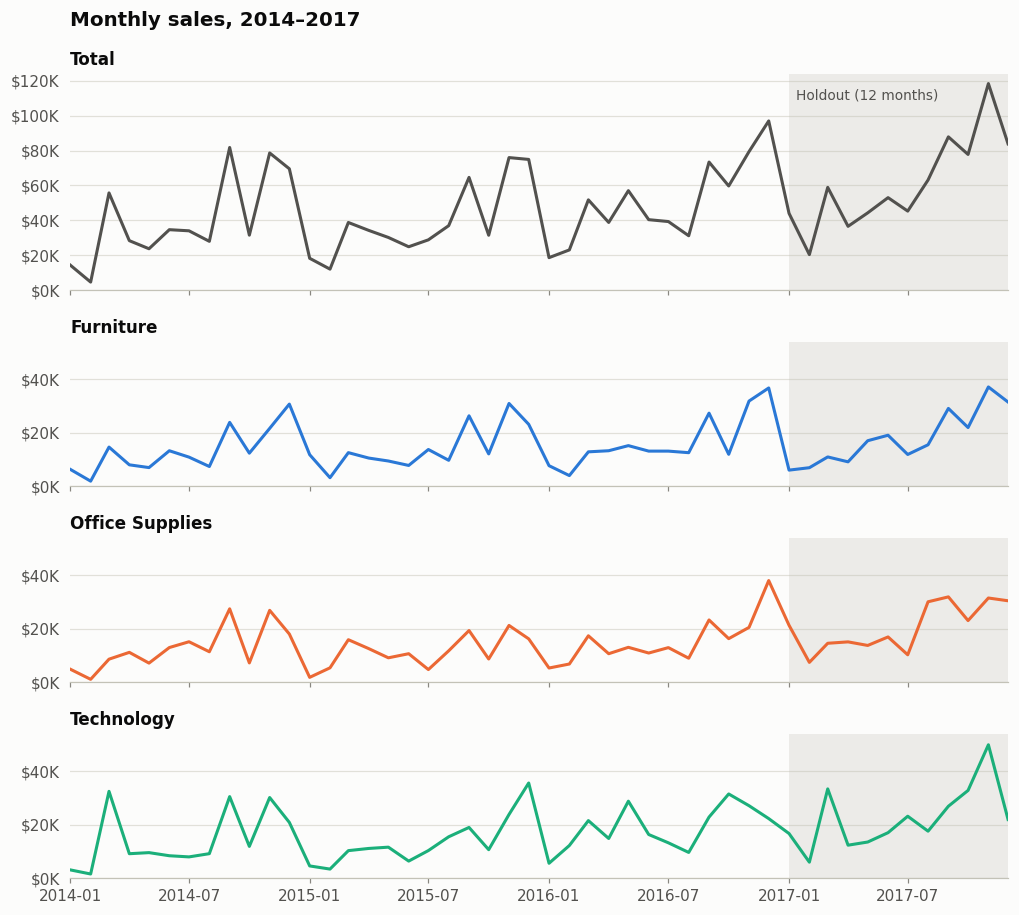

In [4]:
fig, axes = plt.subplots(
    4, 1, figsize=(11, 9.5), sharex=True,
    gridspec_kw={"height_ratios": [1.5, 1, 1, 1], "hspace": 0.32},
)

for ax, name in zip(axes, SERIES):
    ax.plot(sales.index, sales[name], color=SERIES_COLORS[name])
    ax.axvspan(holdout.index.min(), sales.index.max(), color=AXIS, alpha=0.28, lw=0)
    ax.set_title(name)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(thousands)
    ax.margins(x=0)

# Same scale on the three category panels
category_top = sales[CATEGORIES].max().max() * 1.08
for ax in axes[1:]:
    ax.set_ylim(0, category_top)

axes[0].text(
    holdout.index[0] + pd.Timedelta(days=10), axes[0].get_ylim()[1] * 0.93,
    f"Holdout ({HOLDOUT_MONTHS} months)", color=INK_SECONDARY, fontsize=9, va="top",
)
fig.suptitle("Monthly sales, 2014–2017", x=0.125, ha="left", fontsize=13, fontweight="bold", y=0.94)
fig.savefig(FIGURES_DIR / "01_monthly_sales_overview.png")
plt.show()

### 3.2 — Size and Volatility
`cv` is the coefficient of variation (standard deviation ÷ mean): how much a series swings relative to its own size. A higher value means a harder series to forecast.

In [5]:
summary = pd.DataFrame({
    "mean_monthly_sales": train.mean(),
    "share_of_total": train.mean() / train[TOTAL].mean(),
    "min": train.min(),
    "max": train.max(),
    "cv": train.std() / train.mean(),
})
summary.style.format({
    "mean_monthly_sales": "${:,.0f}", "share_of_total": "{:.0%}",
    "min": "${:,.0f}", "max": "${:,.0f}", "cv": "{:.2f}",
})

,mean_monthly_sales,share_of_total,min,max,cv
Total,"$43,444",100%,"$4,520","$96,999",0.54
Furniture,"$14,628",34%,"$1,840","$36,679",0.60
Office Supplies,"$13,137",30%,"$1,072","$37,998",0.59
Technology,"$15,678",36%,"$1,609","$35,632",0.60


### 3.3 — Yearly Sales and Growth (training years)

In [6]:
yearly = train.groupby(train.index.year).sum()
yearly.index.name = "year"
growth = yearly.pct_change()

print("--- Yearly sales ---")
print(yearly.round(0).astype(int).to_string())
print("\n--- Year-over-year growth ---")
print(growth.dropna().map("{:+.1%}".format).to_string())

--- Yearly sales ---
       Total  Furniture  Office Supplies  Technology
year                                                
2014  484247     157193           151776      175278
2015  470533     170518           137233      162781
2016  609206     198901           183940      226364

--- Year-over-year growth ---
       Total Furniture Office Supplies Technology
year                                             
2015   -2.8%     +8.5%           -9.6%      -7.1%
2016  +29.5%    +16.6%          +34.0%     +39.1%


---
## 4. SEASONALITY
> **Goal:** Find which calendar months sell above or below average, and check that the pattern repeats from year to year. A pattern that repeats is one a seasonal model can use.

### 4.1 — Each Year Overlaid by Calendar Month
If the three lines rise and fall together, the seasonality is stable.

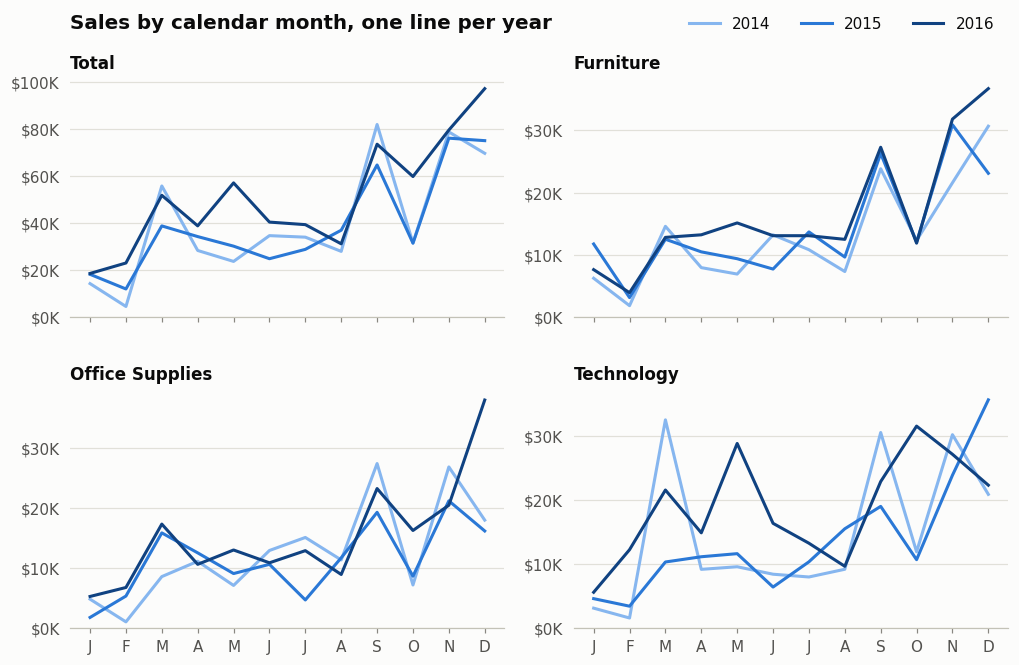

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True, gridspec_kw={"hspace": 0.3, "wspace": 0.16})
years = sorted(train.index.year.unique())

for ax, name in zip(axes.flat, SERIES):
    for year, color in zip(years, ORDINAL_BLUES):
        one_year = train.loc[train.index.year == year, name]
        ax.plot(one_year.index.month, one_year.values, color=color, label=str(year))
    ax.set_title(name)
    ax.set_ylim(0, None)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([m[0] for m in MONTH_LABELS])
    ax.yaxis.set_major_formatter(thousands)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.9, 0.985), ncol=len(years))
fig.suptitle("Sales by calendar month, one line per year", x=0.125, ha="left", fontsize=13, fontweight="bold", y=0.97)
fig.savefig(FIGURES_DIR / "02_seasonal_year_lines.png")
plt.show()

### 4.2 — Seasonal Index
Each month's sales divided by the average month of its own year, then averaged across the three training years. Dividing by the year's average removes the growth trend, so `1.00` means an average month, `1.50` means 50% above average, and `0.50` means half.

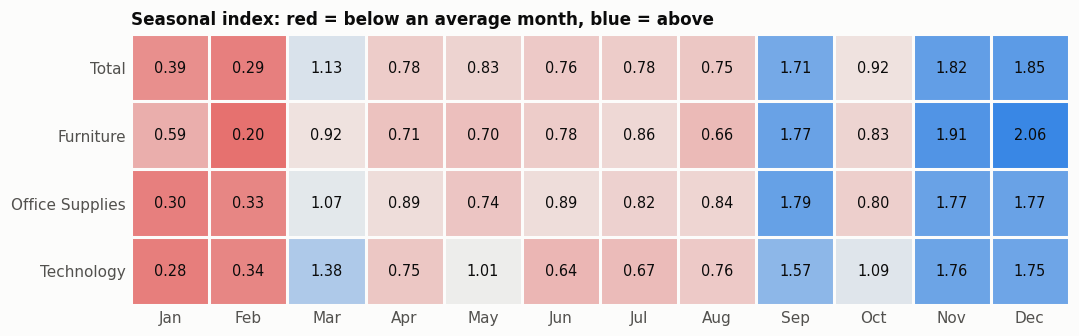

In [8]:
relative = train / train.groupby(train.index.year).transform("mean")
seasonal_index = relative.groupby(relative.index.month).mean().T
seasonal_index.columns = MONTH_LABELS

spread = np.abs(seasonal_index.values - 1).max()

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.imshow(seasonal_index.values, cmap=DIVERGING, vmin=1 - spread, vmax=1 + spread, aspect="auto")
ax.set_xticks(range(12), MONTH_LABELS)
ax.set_yticks(range(len(SERIES)), SERIES)
ax.grid(False)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
# White gaps between cells
ax.set_xticks(np.arange(-0.5, 12), minor=True)
ax.set_yticks(np.arange(-0.5, len(SERIES)), minor=True)
ax.grid(which="minor", color=plt.rcParams["figure.facecolor"], linewidth=2)
ax.tick_params(which="minor", length=0)

for row in range(seasonal_index.shape[0]):
    for col in range(12):
        ax.text(col, row, f"{seasonal_index.iat[row, col]:.2f}", ha="center", va="center", color=INK, fontsize=9.5)

ax.set_title("Seasonal index: red = below an average month, blue = above")
fig.savefig(FIGURES_DIR / "03_seasonal_index.png")
plt.show()

In [9]:
peaks = pd.DataFrame({
    "top_3_months": seasonal_index.apply(lambda row: ", ".join(row.nlargest(3).index), axis=1),
    "bottom_3_months": seasonal_index.apply(lambda row: ", ".join(row.nsmallest(3).index), axis=1),
    "peak_vs_trough": seasonal_index.max(axis=1) / seasonal_index.min(axis=1),
})
peaks.style.format({"peak_vs_trough": "{:.1f}×"})

,top_3_months,bottom_3_months,peak_vs_trough
Total,"Dec, Nov, Sep","Feb, Jan, Aug",6.4×
Furniture,"Dec, Nov, Sep","Feb, Jan, Aug",10.3×
Office Supplies,"Sep, Dec, Nov","Jan, Feb, May",6.1×
Technology,"Nov, Dec, Sep","Jan, Feb, Jun",6.2×


---
## 5. DECOMPOSITION
> **Goal:** Split each series into **trend** (the slow direction), **seasonal** (the pattern that repeats every 12 months) and **residual** (what neither explains), and measure how strong each part is.

We use STL (Seasonal-Trend decomposition using Loess) with two settings:
- `robust=True`, so a single unusually large month lands in the residual instead of distorting the trend or the seasonal pattern.
- A **fixed seasonal pattern** (the same twelve values every year). STL can let the pattern evolve from year to year, but with only three years it then fits the first and last year almost exactly and reports no residual there, which overstates how seasonal the series are.

### 5.1 — STL Components

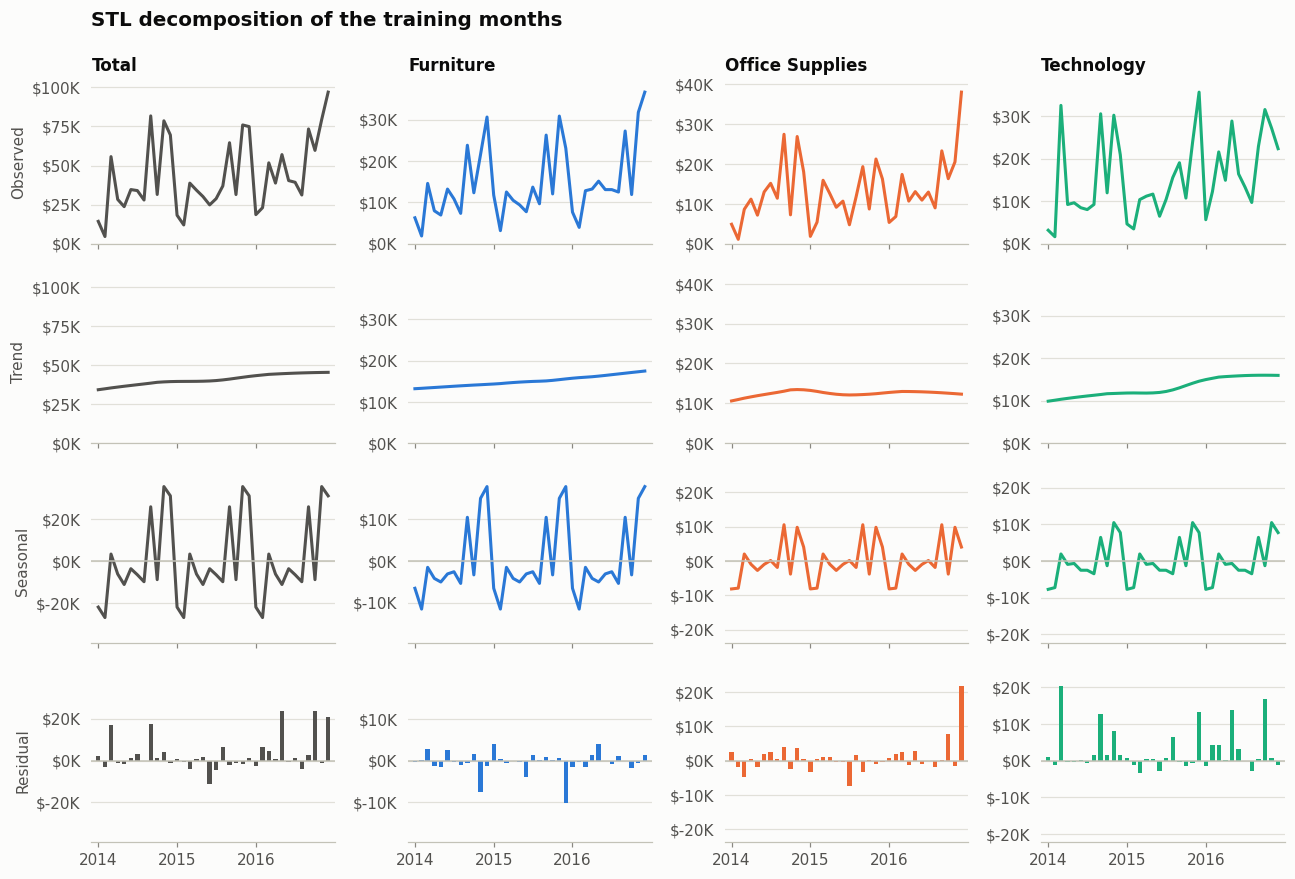

In [10]:
# seasonal=101 is far longer than the three years of data and seasonal_deg=0 fits a
# constant, so each calendar month gets one seasonal value shared by all years.
decompositions = {
    name: STL(train[name], period=12, seasonal=101, seasonal_deg=0, robust=True).fit()
    for name in SERIES
}

components = ["observed", "trend", "seasonal", "resid"]
row_labels = ["Observed", "Trend", "Seasonal", "Residual"]

fig, axes = plt.subplots(4, 4, figsize=(14, 9), sharex=True, gridspec_kw={"hspace": 0.22, "wspace": 0.3})

for col, name in enumerate(SERIES):
    result = decompositions[name]
    color = SERIES_COLORS[name]
    swing = max(result.seasonal.abs().max(), result.resid.abs().max()) * 1.1

    for row, component in enumerate(components):
        ax = axes[row, col]
        values = getattr(result, component)
        if component == "resid":
            ax.bar(values.index, values.values, width=20, color=color)
        else:
            ax.plot(values.index, values.values, color=color)

        if component in ("observed", "trend"):
            ax.set_ylim(0, result.observed.max() * 1.08)
        else:
            # Seasonal and residual share a scale, so their sizes are comparable
            ax.set_ylim(-swing, swing)
            ax.axhline(0, color=AXIS, linewidth=1)

        ax.yaxis.set_major_formatter(thousands)
        ax.margins(x=0.02)
        ax.set_xticks(pd.to_datetime(["2014-01-01", "2015-01-01", "2016-01-01"]), ["2014", "2015", "2016"])
        if row == 0:
            ax.set_title(name)
        if col == 0:
            ax.set_ylabel(row_labels[row])

fig.suptitle("STL decomposition of the training months", x=0.125, ha="left", fontsize=13, fontweight="bold", y=0.95)
fig.savefig(FIGURES_DIR / "04_stl_decomposition.png")
plt.show()

### 5.2 — Strength of Trend and Seasonality
Both measures run from 0 to 1 (Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*). They compare the residual's variance with the variance of the residual plus the component: near 1 means the component dominates the noise, near 0 means it is lost in it.

In [11]:
def component_strength(result):
    resid_var = result.resid.var()
    return {
        "trend_strength": max(0, 1 - resid_var / (result.trend + result.resid).var()),
        "seasonal_strength": max(0, 1 - resid_var / (result.seasonal + result.resid).var()),
        "residual_std": result.resid.std(),
        "residual_std_vs_mean": result.resid.std() / result.observed.mean(),
    }

strength = pd.DataFrame({name: component_strength(result) for name, result in decompositions.items()}).T
strength.style.format({
    "trend_strength": "{:.2f}", "seasonal_strength": "{:.2f}",
    "residual_std": "${:,.0f}", "residual_std_vs_mean": "{:.0%}",
})

,trend_strength,seasonal_strength,residual_std,residual_std_vs_mean
Total,0.26,0.87,"$7,979",18%
Furniture,0.18,0.90,"$2,663",18%
Office Supplies,0.04,0.65,"$4,480",34%
Technology,0.16,0.57,"$5,808",37%


---
## 6. MODEL DIAGNOSTICS
> **Goal:** Answer the two questions the models need settled: is the seasonality additive or multiplicative (Holt-Winters), and does the series need differencing (SARIMA)?

### 6.1 — Additive or Multiplicative Seasonality?
- **Additive:** the seasonal swing is a fixed dollar amount, whatever the sales level.
- **Multiplicative:** the swing is a fixed percentage, so it grows as sales grow.

If the within-year standard deviation grows in step with the yearly mean (so `cv` stays flat), the pattern is multiplicative. If the standard deviation stays flat while the mean grows, it is additive.

In [12]:
by_year = train.groupby(train.index.year)
swing_by_year = pd.concat({"mean": by_year.mean(), "std": by_year.std(), "cv": by_year.std() / by_year.mean()}, axis=1)
swing_by_year = swing_by_year.swaplevel(axis=1)[SERIES]
swing_by_year.index.name = "year"

swing_by_year.style.format(
    {(name, stat): ("{:.2f}" if stat == "cv" else "${:,.0f}") for name in SERIES for stat in ("mean", "std", "cv")}
)

### 6.2 — Stationarity Tests
SARIMA needs a series whose mean and variance do not drift. Two tests with opposite null hypotheses are read together:

| Test | Null hypothesis | Stationary when |
|---|---|---|
| ADF | the series has a unit root (non-stationary) | p < 0.05 |
| KPSS | the series is stationary | p > 0.05 |

Each is run on the series as it is, after a first difference (`d=1`) and after a seasonal difference (`D=1`). With only 36 months both tests have low power, so they are a guide, not a verdict.

In [13]:
def stationarity_row(values):
    adf_p = adfuller(values, maxlag=6, autolag="AIC", result_object=True).pvalue
    with warnings.catch_warnings():
        # KPSS warns when the p-value falls outside its lookup table (reported as 0.01 or 0.10)
        warnings.simplefilter("ignore", InterpolationWarning)
        kpss_p = kpss(values, regression="c", nlags="auto", result_object=True).pvalue
    return {"adf_p": adf_p, "kpss_p": kpss_p, "stationary": (adf_p < 0.05) and (kpss_p > 0.05)}

transforms = {
    "level": lambda s: s,
    "first difference (d=1)": lambda s: s.diff().dropna(),
    "seasonal difference (D=1)": lambda s: s.diff(12).dropna(),
}

stationarity = pd.DataFrame({
    (name, label): stationarity_row(transform(train[name]))
    for name in SERIES for label, transform in transforms.items()
}).T
stationarity.index.names = ["series", "transform"]
stationarity.style.format({"adf_p": "{:.3f}", "kpss_p": "{:.3f}"})

### 6.3 — Autocorrelation (ACF and PACF)
How strongly each month correlates with the months before it. A bar outside the dashed band is statistically different from zero. A spike at **lag 12** is the signature of yearly seasonality.

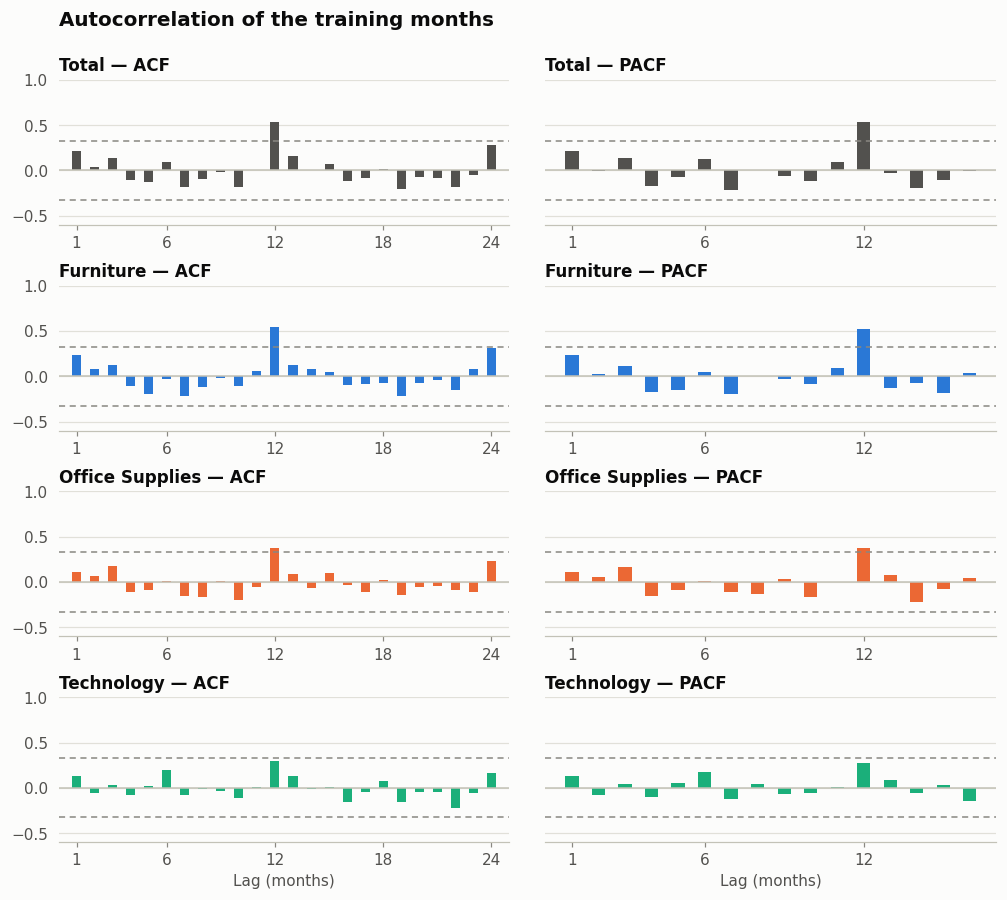

In [14]:
ACF_LAGS, PACF_LAGS = 24, 16
band = 1.96 / np.sqrt(len(train))

fig, axes = plt.subplots(4, 2, figsize=(11, 9), sharey=True, gridspec_kw={"hspace": 0.42, "wspace": 0.08})

for row, name in enumerate(SERIES):
    correlations = {
        "ACF": acf(train[name], nlags=ACF_LAGS)[1:],
        "PACF": pacf(train[name], nlags=PACF_LAGS, method="ywm")[1:],
    }
    for ax, (kind, values) in zip(axes[row], correlations.items()):
        lags = np.arange(1, len(values) + 1)
        ax.bar(lags, values, width=0.5, color=SERIES_COLORS[name])
        ax.axhline(0, color=AXIS, linewidth=1)
        for level in (band, -band):
            ax.axhline(level, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
        ax.set_title(f"{name} — {kind}")
        ax.set_ylim(-0.6, 1)
        ax.set_xticks([1, 6, 12, 18, 24][: 5 if kind == "ACF" else 3])
        ax.set_xlim(0, len(values) + 1)

for ax in axes[-1]:
    ax.set_xlabel("Lag (months)")
fig.suptitle("Autocorrelation of the training months", x=0.125, ha="left", fontsize=13, fontweight="bold", y=0.95)
fig.savefig(FIGURES_DIR / "05_acf_pacf.png")
plt.show()

In [15]:
lag_12 = pd.DataFrame({
    "acf_lag_1": {name: acf(train[name], nlags=12)[1] for name in SERIES},
    "acf_lag_12": {name: acf(train[name], nlags=12)[12] for name in SERIES},
})
lag_12["significance_band"] = band
lag_12.round(2)

,acf_lag_1,acf_lag_12,significance_band
Total,0.21,0.54,0.33
Furniture,0.23,0.54,0.33
Office Supplies,0.12,0.37,0.33
Technology,0.13,0.30,0.33


---
## 7. FINDINGS

All figures below come from the 36 training months (Jan 2014 → Dec 2016).

| # | Finding | Evidence | What it means for the models |
|---|---|---|---|
| 1 | **Seasonality is the main signal.** | September, November and December sell 1.6–2.1× an average month; January and February only 0.2–0.6×. Lag-12 autocorrelation is 0.54 for Total and Furniture. | Every main model needs a 12-month seasonal component. |
| 2 | **The seasonal shape is the same in all three categories.** | Each one peaks in Sep / Nov / Dec, bottoms in Jan / Feb, and (except Technology) dips in October between the two peaks. | One model family can serve all four series; no category needs special handling. |
| 3 | **Month-to-month memory is weak.** | Lag-1 autocorrelation is 0.12–0.23, inside the ±0.33 noise band for every series. | The plain naive forecast (repeat last month) should do badly. The **seasonal naive** forecast is the benchmark that will be hard to beat. |
| 4 | **The trend is weak and uneven.** | Total sales fell 2.8% in 2015 and rose 29.5% in 2016. Trend strength is 0.26 for Total and 0.04–0.18 for the categories. | Two growth observations are not enough to trust a straight-line trend. Test a damped trend in Holt-Winters alongside the standard one. |
| 5 | **Furniture is the most predictable category; Technology the least.** | Seasonal strength: Furniture 0.90, Office Supplies 0.65, Technology 0.57. Residual noise is 18% of mean sales for Furniture, 34% for Office Supplies and 37% for Technology. | Expect clearly higher MAPE/WAPE on Office Supplies and Technology, and wider confidence intervals. Their noise sets a floor no model will get under. |
| 6 | **Additive vs multiplicative is not settled.** | For Total, mean monthly sales rose 26% from 2014 to 2016 while the within-year standard deviation stayed near \$21–25K (additive behaviour). For Furniture the two grew together, cv 0.64 → 0.60 (multiplicative behaviour). | Fit Holt-Winters both ways and choose on the training data. Three years cannot decide it by inspection. |
| 7 | **The stationarity tests do not agree on differencing.** | ADF rejects a unit root on the undifferenced series for all four (p ≤ 0.002), while KPSS is borderline (p = 0.04–0.08). Results after a seasonal difference are inconsistent, with only 24 months left to test. | For SARIMA, compare a small grid — `d` and `D` each in {0, 1}, with `p, q, P, Q ≤ 1` — by AICc on the training months instead of fixing the orders from these tests. |

### Limits of this analysis
- **Three years is a short history for yearly seasonality.** Each calendar month has been observed only three times, so one unusual month moves its seasonal index a lot. Technology's March index (1.38) is an example: it rests largely on March 2014.
- **Large single months are present**, especially in Technology (see the residual row in 5.1). They are kept in the data: they are real sales, and the models have to cope with them.
- **The holdout has not been analysed.** It appears only in the overview chart (3.1).

> **Next step:** baselines (naive and seasonal naive) and the validation harness — MAPE and WAPE measured on the 12 holdout months.